# Real-Time Performance Evaluation: eBPF + ML Bottleneck Diagnosis

This notebook analyzes the CSV files produced by the benchmark runner:

- `runtime_benchmark_results/cycle_metrics.csv` — per-cycle timings and monitoring intervals
- `runtime_benchmark_results/run_summary.csv` — optional run-level summaries
- `runtime_benchmark_results/system_resource_metrics.csv` — optional CPU/memory measurements

It is designed to work with the column names proposed in the GitHub Copilot benchmark prompt and common variants. If a column is not detected, inspect the column names printed below and update the aliases in the configuration cell.

**Important:** The notebook analyzes measurements; it does not create or simulate benchmark results. Missing data is reported as unavailable. A single run can characterize that run, but cannot establish repeatability or broad generalization.


In [ ]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Change this if your benchmark output is stored elsewhere.
RESULTS_DIR = Path("runtime_benchmark_results")

CYCLE_FILE = RESULTS_DIR / "cycle_metrics.csv"
SUMMARY_FILE = RESULTS_DIR / "run_summary.csv"
RESOURCE_FILE = RESULTS_DIR / "system_resource_metrics.csv"

# If running the notebook from inside the results folder, allow that layout too.
if not CYCLE_FILE.exists() and Path("cycle_metrics.csv").exists():
    RESULTS_DIR = Path(".")
    CYCLE_FILE = RESULTS_DIR / "cycle_metrics.csv"
    SUMMARY_FILE = RESULTS_DIR / "run_summary.csv"
    RESOURCE_FILE = RESULTS_DIR / "system_resource_metrics.csv"

if not CYCLE_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {CYCLE_FILE}. Put cycle_metrics.csv in "
        f"{RESULTS_DIR.resolve()} or update RESULTS_DIR above."
    )

cycles = pd.read_csv(CYCLE_FILE)
summary = pd.read_csv(SUMMARY_FILE) if SUMMARY_FILE.exists() else None
resources = pd.read_csv(RESOURCE_FILE) if RESOURCE_FILE.exists() else None

print("Cycle metrics:", cycles.shape)
print("Cycle columns:", cycles.columns.tolist())
print("\nRun summary:", None if summary is None else summary.shape)
print("Resource metrics:", None if resources is None else resources.shape)


Cycle metrics: (62, 28)
Cycle columns: ['run_id', 'comparison_id', 'repetition_index', 'condition', 'workload_type', 'intensity', 'workload_workers', 'cycle_id', 'phase', 'cycle_start_ns', 'cycle_end_ns', 'map_read_ms', 'aggregation_ms', 'feature_ms', 'rf_inference_ms', 'classifier_inference_ms', 'mlp_inference_ms', 'model_class', 'output_ms', 'detection_latency_ms', 'total_cycle_ms', 'records_processed', 'high_predictions', 'configured_interval_ms', 'actual_cycle_interval_ms', 'deadline_missed', 'cycle_status', 'error']

Run summary: (2, 42)
Resource metrics: (660, 20)


## 1. Normalize common column-name variants

The following cell looks for common aliases for total diagnosis latency, actual monitoring interval, configured interval, timestamps, deadline misses, and stage timings. It converts timing columns ending in `_ns` to milliseconds. Review the detected fields before relying on the plots.


In [ ]:
def norm_name(name):
    return str(name).strip().lower().replace(" ", "_").replace("-", "_")

original_columns = list(cycles.columns)
col_lookup = {norm_name(c): c for c in original_columns}

ALIASES = {
    "total_latency": [
        "total_cycle_ms", "total_latency_ms", "total_diagnosis_ms",
        "diagnosis_latency_ms", "total_ms", "cycle_duration_ms",
        "total_cycle_ns", "total_latency_ns", "total_diagnosis_ns",
        "diagnosis_latency_ns", "total_ns"
    ],
    "actual_interval": [
        "actual_cycle_interval_ms", "actual_interval_ms", "cycle_interval_ms",
        "observed_interval_ms", "start_to_start_ms", "actual_cycle_interval_ns",
        "actual_interval_ns", "cycle_interval_ns", "observed_interval_ns"
    ],
    "configured_interval": [
        "configured_interval_ms", "monitoring_interval_ms",
        "target_interval_ms", "configured_interval_ns",
        "monitoring_interval_ns", "target_interval_ns"
    ],
    "timestamp": [
        "cycle_start_time", "cycle_start_timestamp", "timestamp",
        "start_timestamp", "cycle_start", "start_time", "elapsed_s",
        "elapsed_seconds", "elapsed_time_s"
    ],
    "deadline_missed": [
        "deadline_missed", "missed_deadline", "deadline_miss",
        "deadline_missed_flag", "missed_deadline_flag"
    ],
    "cycle_id": ["cycle_id", "cycle", "iteration", "iteration_id"],
    "run_id": ["run_id", "experiment_id", "trial_id"],
    "records": ["records_processed", "record_count", "num_records", "rows_processed"],
    "high_predictions": ["high_predictions", "num_high_predictions", "high_count"]
}

def find_column(key, frame=cycles):
    lookup = {norm_name(c): c for c in frame.columns}
    for alias in ALIASES.get(key, []):
        if norm_name(alias) in lookup:
            return lookup[norm_name(alias)]
    return None

def timing_to_ms(series, column_name):
    name = norm_name(column_name)
    values = pd.to_numeric(series, errors="coerce")
    if name.endswith("_ns") or "_ns_" in name:
        return values / 1_000_000
    if name.endswith("_us") or "_us_" in name:
        return values / 1_000
    if name.endswith("_s") and not name.endswith("_ms"):
        return values * 1_000
    return values

latency_col = find_column("total_latency")
interval_col = find_column("actual_interval")
configured_col = find_column("configured_interval")
timestamp_col = find_column("timestamp")
deadline_col = find_column("deadline_missed")
cycle_id_col = find_column("cycle_id")
run_id_col = find_column("run_id")

print("Detected columns:")
for label, value in [
    ("Total diagnosis/cycle latency", latency_col),
    ("Actual start-to-start interval", interval_col),
    ("Configured interval", configured_col),
    ("Timestamp / elapsed time", timestamp_col),
    ("Deadline-missed flag", deadline_col),
    ("Cycle ID", cycle_id_col),
    ("Run ID", run_id_col),
]:
    print(f"  {label}: {value}")

data = cycles.copy()

if latency_col:
    data["latency_ms"] = timing_to_ms(data[latency_col], latency_col)
if interval_col:
    data["actual_interval_ms"] = timing_to_ms(data[interval_col], interval_col)
if configured_col:
    data["configured_interval_ms"] = timing_to_ms(data[configured_col], configured_col)

if timestamp_col:
    raw_ts = data[timestamp_col]
    parsed_dt = pd.to_datetime(raw_ts, errors="coerce")
    if parsed_dt.notna().sum() >= max(1, int(0.5 * len(data))):
        data["plot_time"] = parsed_dt
        data = data.sort_values("plot_time")
    else:
        numeric_ts = pd.to_numeric(raw_ts, errors="coerce")
        data["plot_time"] = numeric_ts
        # Treat common elapsed-time fields as seconds; timestamps in ns are converted.
        tname = norm_name(timestamp_col)
        if tname.endswith("_ns") or "timestamp_ns" in tname:
            data["plot_time"] = numeric_ts / 1e9
        elif tname.endswith("_ms"):
            data["plot_time"] = numeric_ts / 1e3
        # Otherwise numeric values are assumed to be elapsed seconds or a monotonic clock.
else:
    data["plot_time"] = np.arange(len(data))

if cycle_id_col:
    data = data.sort_values(cycle_id_col, kind="stable")
else:
    data = data.reset_index(drop=True)

display(data.head())


Detected columns:
  Total diagnosis/cycle latency: total_cycle_ms
  Actual start-to-start interval: actual_cycle_interval_ms
  Configured interval: configured_interval_ms
  Timestamp / elapsed time: None
  Deadline-missed flag: deadline_missed
  Cycle ID: cycle_id
  Run ID: run_id


,run_id,comparison_id,repetition_index,condition,workload_type,intensity,workload_workers,cycle_id,phase,cycle_start_ns,...,records_processed,high_predictions,configured_interval_ms,actual_cycle_interval_ms,deadline_missed,cycle_status,error,latency_ms,actual_interval_ms,plot_time
0,cpu4-monitored-r1,cpu4-pilot-r1,1,ebpf_plus_diagnosis,cpu,medium,4,1,warmup,15621319213746,...,819,4,5000.0,NaN,NaN,completed,NaN,192.620618,NaN,0
1,cpu4-monitored-r1,cpu4-pilot-r1,1,ebpf_plus_diagnosis,cpu,medium,4,2,warmup,15626511952688,...,943,4,5000.0,5192.738942,NaN,completed,NaN,216.606097,5192.738942,1
2,cpu4-monitored-r1,cpu4-pilot-r1,1,ebpf_plus_diagnosis,cpu,medium,4,3,warmup,15631728698789,...,1076,5,5000.0,5216.746101,NaN,completed,NaN,222.317390,5216.746101,2
3,cpu4-monitored-r1,cpu4-pilot-r1,1,ebpf_plus_diagnosis,cpu,medium,4,4,warmup,15636951126478,...,1171,5,5000.0,5222.427689,NaN,completed,NaN,226.202504,5222.427689,3
4,cpu4-monitored-r1,cpu4-pilot-r1,1,ebpf_plus_diagnosis,cpu,medium,4,5,warmup,15642177446113,...,1283,4,5000.0,5226.319635,NaN,completed,NaN,279.524330,5226.319635,4


## 2. Per-cycle latency and summary statistics

This is the primary diagnosis-latency analysis. Median and p95 are useful because occasional slow cycles can be hidden by the mean. The interpretation depends on what the benchmark runner times: ideally, total latency includes the complete diagnosis path, and stage timings are not added again if they are already included in the total.


,Value
Cycles with latency measurements,62.000
Mean latency (ms),392.035
Median latency (ms),384.924
P95 latency (ms),564.458
P99 latency (ms),630.974
Minimum latency (ms),192.621
Maximum latency (ms),673.396
Latency standard deviation (ms),111.557


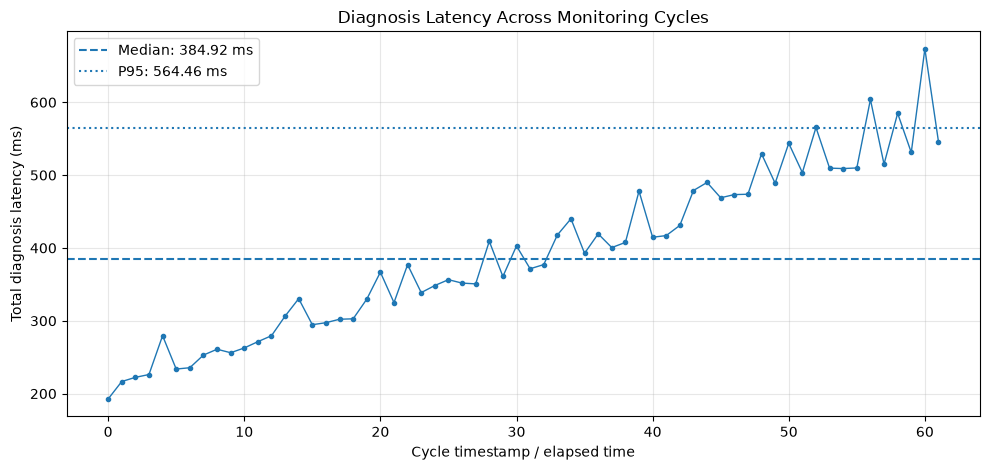

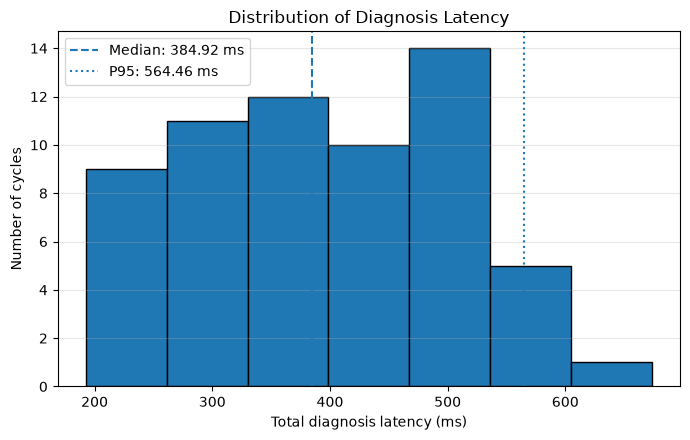

In [ ]:
if "latency_ms" not in data.columns or data["latency_ms"].notna().sum() == 0:
    print("No recognized total-latency column found. Check the printed columns and update ALIASES.")
else:
    latency = data["latency_ms"].dropna()
    latency_stats = pd.Series({
        "Cycles with latency measurements": int(latency.count()),
        "Mean latency (ms)": latency.mean(),
        "Median latency (ms)": latency.median(),
        "P95 latency (ms)": latency.quantile(0.95),
        "P99 latency (ms)": latency.quantile(0.99),
        "Minimum latency (ms)": latency.min(),
        "Maximum latency (ms)": latency.max(),
        "Latency standard deviation (ms)": latency.std()
    })
    display(latency_stats.to_frame("Value").round(3))

    fig, ax = plt.subplots(figsize=(10, 4.8))
    x = data["plot_time"]
    ax.plot(x, data["latency_ms"], marker=".", linewidth=1)
    ax.axhline(latency.median(), linestyle="--", label=f"Median: {latency.median():.2f} ms")
    ax.axhline(latency.quantile(0.95), linestyle=":", label=f"P95: {latency.quantile(0.95):.2f} ms")
    ax.set_title("Diagnosis Latency Across Monitoring Cycles")
    ax.set_xlabel("Cycle timestamp / elapsed time")
    ax.set_ylabel("Total diagnosis latency (ms)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(latency, bins="auto", edgecolor="black")
    ax.axvline(latency.median(), linestyle="--", label=f"Median: {latency.median():.2f} ms")
    ax.axvline(latency.quantile(0.95), linestyle=":", label=f"P95: {latency.quantile(0.95):.2f} ms")
    ax.set_title("Distribution of Diagnosis Latency")
    ax.set_xlabel("Total diagnosis latency (ms)")
    ax.set_ylabel("Number of cycles")
    ax.legend()
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


## 3. Actual monitoring interval versus configured interval

Use this plot to show whether the system actually produces diagnosis cycles at the intended cadence. The interval should be start-to-start time between consecutive cycles, not merely the duration of inference. If the benchmark runner does not record actual intervals, the notebook cannot infer them reliably from latency alone.


,Value
Cycles with interval measurements,61.000
Mean actual interval (ms),5389.646
Median actual interval (ms),5377.270
P95 actual interval (ms),5565.604
Minimum actual interval (ms),5192.739
Maximum actual interval (ms),5673.756


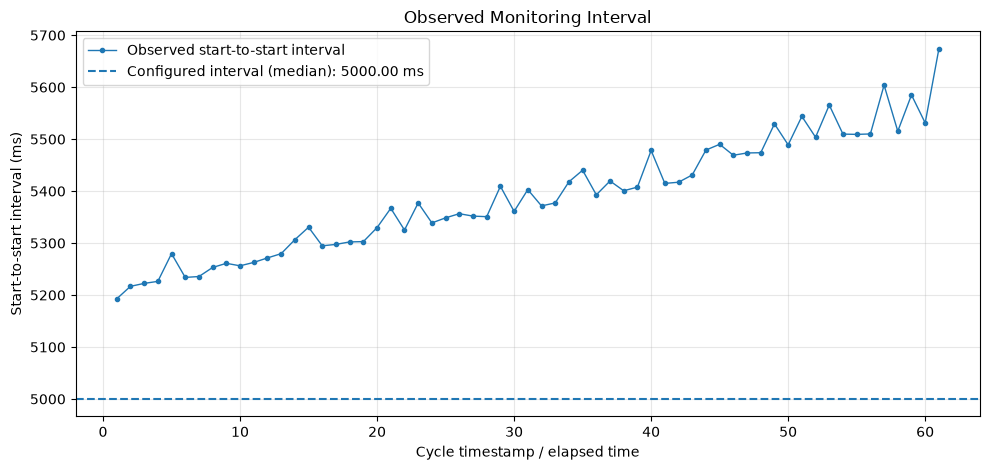

Median interval deviation: 377.27 ms
P95 interval deviation: 565.60 ms
Note: a positive deviation means the observed interval exceeded the configured target.


In [ ]:
if "actual_interval_ms" not in data.columns or data["actual_interval_ms"].notna().sum() == 0:
    print("No recognized actual monitoring-interval column found.")
else:
    observed = data["actual_interval_ms"].dropna()
    interval_stats = pd.Series({
        "Cycles with interval measurements": int(observed.count()),
        "Mean actual interval (ms)": observed.mean(),
        "Median actual interval (ms)": observed.median(),
        "P95 actual interval (ms)": observed.quantile(0.95),
        "Minimum actual interval (ms)": observed.min(),
        "Maximum actual interval (ms)": observed.max()
    })
    display(interval_stats.to_frame("Value").round(3))

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(data["plot_time"], data["actual_interval_ms"], marker=".", linewidth=1,
            label="Observed start-to-start interval")
    if "configured_interval_ms" in data.columns and data["configured_interval_ms"].notna().any():
        target = data["configured_interval_ms"].dropna().median()
        ax.axhline(target, linestyle="--", label=f"Configured interval (median): {target:.2f} ms")
    ax.set_title("Observed Monitoring Interval")
    ax.set_xlabel("Cycle timestamp / elapsed time")
    ax.set_ylabel("Start-to-start interval (ms)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

    if "configured_interval_ms" in data.columns:
        paired = data[["actual_interval_ms", "configured_interval_ms"]].dropna()
        if not paired.empty:
            deviation = paired["actual_interval_ms"] - paired["configured_interval_ms"]
            print(f"Median interval deviation: {deviation.median():.2f} ms")
            print(f"P95 interval deviation: {deviation.quantile(0.95):.2f} ms")
            print("Note: a positive deviation means the observed interval exceeded the configured target.")


## 4. Deadline misses

Only use this metric if the benchmark runner defines a deadline clearly (for example, a cycle must finish within the configured monitoring interval). A missing flag is not treated as zero misses.


In [ ]:
if deadline_col is None:
    print("No deadline-missed flag recorded; deadline-miss rate is unavailable.")
else:
    raw = data[deadline_col]
    if raw.dtype == bool:
        missed = raw
    else:
        normalized = raw.astype(str).str.strip().str.lower()
        true_values = {"1", "true", "yes", "y", "missed", "deadline_missed"}
        false_values = {"0", "false", "no", "n", "not_missed", "on_time"}
        missed = normalized.map(lambda v: True if v in true_values else (False if v in false_values else np.nan))
    valid = missed.dropna()
    if len(valid) == 0:
        print("Deadline flag exists, but its values could not be interpreted. Inspect:", data[deadline_col].unique()[:20])
    else:
        rate = valid.astype(bool).mean() * 100
        print(f"Cycles with a valid deadline flag: {len(valid)}")
        print(f"Missed-deadline rate: {rate:.2f}%")
        print(f"Missed deadlines: {int(valid.astype(bool).sum())} / {len(valid)}")


Deadline flag exists, but its values could not be interpreted. Inspect: [nan]


## 5. Stage timing breakdown

This chart is optional. It is useful if the benchmark runner separately records map reading, feature engineering, Random Forest inference, MLP attribution, and output/reporting time. Stage timings should be measured independently; avoid double-counting nested timers.


,Stage,Median (ms),P95 (ms),Mean (ms)
0,Map reading,132.183,192.181,131.855
1,Aggregation,68.377,147.732,75.393
2,Random Forest,107.517,127.930,112.226
3,Output,57.424,95.317,57.897


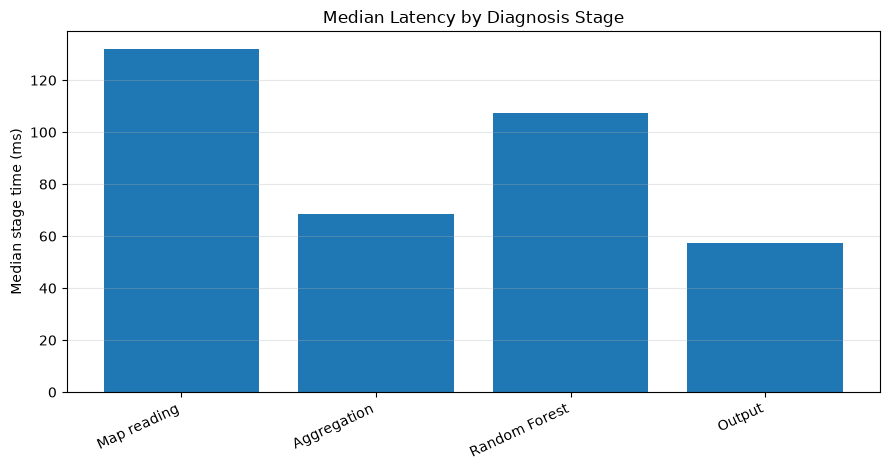

In [ ]:
stage_groups = {
    "Map reading": ["map_read_ms", "map_read_ns", "map_reading_ms", "map_reading_ns"],
    "Aggregation": ["aggregation_ms", "aggregation_ns", "aggregate_ms", "aggregate_ns"],
    "Feature engineering": ["feature_engineering_ms", "feature_engineering_ns", "feature_processing_ms", "feature_processing_ns"],
    "Random Forest": ["rf_inference_ms", "rf_inference_ns", "random_forest_ms", "random_forest_ns", "rf_ms", "rf_ns"],
    "MLP attribution": ["mlp_attribution_ms", "mlp_attribution_ns", "attribution_ms", "attribution_ns"],
    "Output": ["output_ms", "output_ns", "reporting_ms", "reporting_ns"]
}

stage_rows = []
for stage, aliases in stage_groups.items():
    found = None
    lookup = {norm_name(c): c for c in data.columns}
    for alias in aliases:
        if norm_name(alias) in lookup:
            found = lookup[norm_name(alias)]
            break
    if found is not None:
        vals = timing_to_ms(data[found], found).dropna()
        if len(vals):
            stage_rows.append({
                "Stage": stage,
                "Median (ms)": vals.median(),
                "P95 (ms)": vals.quantile(0.95),
                "Mean (ms)": vals.mean()
            })

if not stage_rows:
    print("No recognized stage timing columns found.")
else:
    stage_stats = pd.DataFrame(stage_rows)
    display(stage_stats.round(3))
    fig, ax = plt.subplots(figsize=(9, 4.8))
    positions = np.arange(len(stage_stats))
    ax.bar(positions, stage_stats["Median (ms)"], yerr=None)
    ax.set_xticks(positions)
    ax.set_xticklabels(stage_stats["Stage"], rotation=25, ha="right")
    ax.set_ylabel("Median stage time (ms)")
    ax.set_title("Median Latency by Diagnosis Stage")
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


## 6. CPU and memory overhead (if resource data was collected)

To quantify monitoring overhead, the resource CSV should distinguish baseline workload-only samples from monitored samples (for example, a `mode`, `condition`, or `monitoring_enabled` column). If both conditions are not present, the notebook can show the time series but cannot calculate a defensible overhead comparison.


Resource columns: ['run_id', 'resource_run_id', 'comparison_id', 'repetition_index', 'condition', 'workload_type', 'intensity', 'workload_workers', 'timestamp_ns', 'elapsed_s', 'phase', 'system_cpu_percent', 'system_memory_used_bytes', 'system_memory_used_percent', 'workload_pid', 'workload_process_cpu_percent_one_core', 'workload_process_rss_bytes', 'monitor_pid', 'monitor_process_cpu_percent_one_core', 'monitor_process_rss_bytes']
Detected CPU: system_cpu_percent | memory: None | condition: condition | time: elapsed_s

Samples per condition:


,Samples
condition,
workload_only,330
ebpf_plus_diagnosis,330


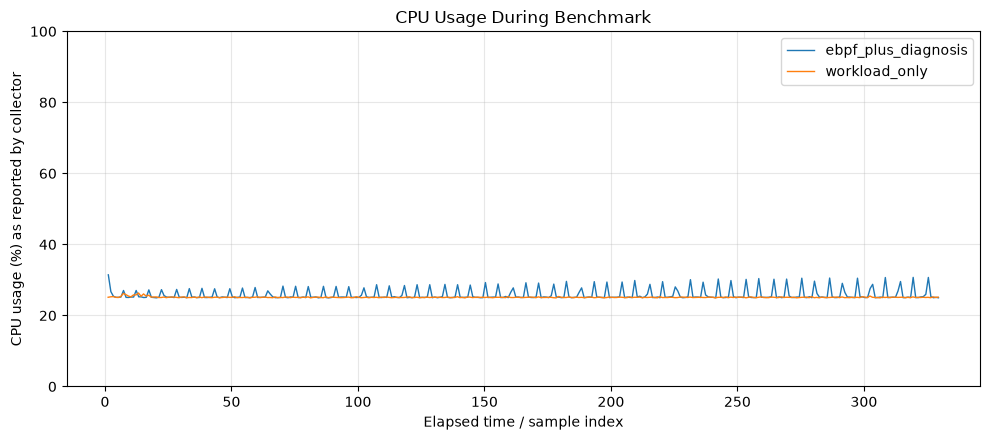


CPU (%) by condition:


,count,mean,median,max
condition,,,,
ebpf_plus_diagnosis,329,25.871,25.141,31.438
workload_only,329,25.123,25.109,26.329


In [ ]:
if resources is None:
    print("No system_resource_metrics.csv found; resource overhead cannot be analyzed.")
else:
    print("Resource columns:", resources.columns.tolist())
    r = resources.copy()
    rlookup = {norm_name(c): c for c in r.columns}

    def resource_col(candidates):
        for candidate in candidates:
            if norm_name(candidate) in rlookup:
                return rlookup[norm_name(candidate)]
        return None

    cpu_col = resource_col(["cpu_percent", "cpu_pct", "process_cpu_percent", "system_cpu_percent", "cpu_usage_percent"])
    mem_col = resource_col(["memory_mb", "rss_mb", "process_memory_mb", "memory_usage_mb", "rss_bytes", "memory_bytes"])
    mode_col = resource_col(["mode", "condition", "scenario", "monitoring_enabled", "experiment_mode"])
    rtime_col = resource_col(["elapsed_s", "elapsed_seconds", "timestamp", "elapsed_time_s"])

    print("Detected CPU:", cpu_col, "| memory:", mem_col, "| condition:", mode_col, "| time:", rtime_col)

    if mem_col:
        r["memory_plot_value"] = pd.to_numeric(r[mem_col], errors="coerce")
        if norm_name(mem_col).endswith("_bytes"):
            r["memory_plot_value"] = r["memory_plot_value"] / (1024 ** 2)
            memory_label = "Memory (MiB)"
        else:
            memory_label = "Memory value (column units)"
    if cpu_col:
        r["cpu_plot_value"] = pd.to_numeric(r[cpu_col], errors="coerce")

    if mode_col:
        print("\nSamples per condition:")
        display(r[mode_col].value_counts(dropna=False).to_frame("Samples"))

    if rtime_col:
        r["resource_plot_time"] = pd.to_numeric(r[rtime_col], errors="coerce")
    else:
        r["resource_plot_time"] = np.arange(len(r))

    if cpu_col:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        if mode_col:
            for mode, grp in r.groupby(mode_col, dropna=False):
                ax.plot(grp["resource_plot_time"], grp["cpu_plot_value"], label=str(mode), linewidth=1)
            ax.legend()
        else:
            ax.plot(r["resource_plot_time"], r["cpu_plot_value"], linewidth=1)
        ax.set_title("CPU Usage During Benchmark")
        ax.set_xlabel("Elapsed time / sample index")
        ax.set_ylabel("CPU usage (%) as reported by collector")
        ax.set_ylim(0, 100)
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

    if mem_col:
        fig, ax = plt.subplots(figsize=(10, 4.5))
        if mode_col:
            for mode, grp in r.groupby(mode_col, dropna=False):
                ax.plot(grp["resource_plot_time"], grp["memory_plot_value"], label=str(mode), linewidth=1)
            ax.legend()
        else:
            ax.plot(r["resource_plot_time"], r["memory_plot_value"], linewidth=1)
        ax.set_title("Memory Usage During Benchmark")
        ax.set_xlabel("Elapsed time / sample index")
        ax.set_ylabel(memory_label)
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

    if mode_col and (cpu_col or mem_col):
        metric_map = {}
        if cpu_col:
            metric_map["CPU (%)"] = "cpu_plot_value"
        if mem_col:
            metric_map[memory_label] = "memory_plot_value"
        for label, col in metric_map.items():
            print(f"\n{label} by condition:")
            display(r.groupby(mode_col)[col].agg(["count", "mean", "median", "max"]).round(3))


## 7. Export compact analysis tables

These summaries can help when writing the paper. Keep the raw benchmark CSVs alongside them so the results remain traceable.


In [ ]:
analysis_dir = RESULTS_DIR / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

if "latency_ms" in data.columns:
    latency = data["latency_ms"].dropna()
    if len(latency):
        pd.DataFrame([{
            "n_cycles": int(len(latency)),
            "mean_latency_ms": latency.mean(),
            "median_latency_ms": latency.median(),
            "p95_latency_ms": latency.quantile(0.95),
            "p99_latency_ms": latency.quantile(0.99),
            "min_latency_ms": latency.min(),
            "max_latency_ms": latency.max(),
            "std_latency_ms": latency.std()
        }]).to_csv(analysis_dir / "latency_summary.csv", index=False)

if "actual_interval_ms" in data.columns:
    intervals = data["actual_interval_ms"].dropna()
    if len(intervals):
        pd.DataFrame([{
            "n_intervals": int(len(intervals)),
            "mean_actual_interval_ms": intervals.mean(),
            "median_actual_interval_ms": intervals.median(),
            "p95_actual_interval_ms": intervals.quantile(0.95),
            "min_actual_interval_ms": intervals.min(),
            "max_actual_interval_ms": intervals.max()
        }]).to_csv(analysis_dir / "interval_summary.csv", index=False)

print(f"Analysis outputs saved under: {analysis_dir.resolve()}")
print("No benchmark values are generated by this notebook; all statistics come from the CSV inputs.")


Analysis outputs saved under: D:\Code\ProjectA\PerformanceBottleneckDiagnosis\src\realtime\runtime_benchmark_results\analysis
No benchmark values are generated by this notebook; all statistics come from the CSV inputs.


## Suggested wording for the paper

Use this only as a structure, and replace the brackets with measured values:

> **Real-Time Performance Evaluation:** We evaluated the runtime behavior of the framework under a concurrent mixed `stress-ng` workload. Across [N] measured diagnosis cycles, the median and 95th-percentile end-to-end diagnosis latencies were [X] ms and [Y] ms, respectively. The observed median start-to-start monitoring interval was [Z] ms, compared with the configured interval of [T] ms. The measured monitoring overhead was [CPU result] and [memory result] relative to the workload-only baseline.

Do not claim real-time responsiveness from inference latency alone. Report the observed monitoring interval too, and state whether map reads were periodic snapshots or session-end reads. If only one run was conducted, explicitly describe it as a single-run evaluation.


BENCHMARK AUDIT
Resource file: D:\Code\ProjectA\PerformanceBottleneckDiagnosis\src\realtime\runtime_benchmark_results\system_resource_metrics.csv
Group summary: D:\Code\ProjectA\PerformanceBottleneckDiagnosis\src\realtime\runtime_benchmark_results\analysis\group_summary.csv
Overhead summary: D:\Code\ProjectA\PerformanceBottleneckDiagnosis\src\realtime\runtime_benchmark_results\analysis\overhead_summary.csv
Resource rows: 660

Runs and sample counts:
                                                   samples  first_elapsed_s  last_elapsed_s  workers  comparison_id
run_id            condition           phase                                                                        
cpu4-baseline-r1  workload_only       measurement      300        30.261591      329.381177        4  cpu4-pilot-r1
                                      warmup            30         0.247757       29.261258        4  cpu4-pilot-r1
cpu4-monitored-r1 ebpf_plus_diagnosis measurement      300        30.339359      3

,condition,metric,n,mean,median,p95,max,zero_fraction
0,ebpf_plus_diagnosis,Host CPU (%),300,25.880,25.140,29.603,30.726,0.000
1,ebpf_plus_diagnosis,System memory used (%),300,28.002,27.998,28.189,28.260,0.000
2,ebpf_plus_diagnosis,Recorded workload-process CPU (% of one core),299,0.000,0.000,0.000,0.000,1.000
3,ebpf_plus_diagnosis,Workload-process RSS (MiB),299,5.809,5.809,5.809,5.809,0.000
4,ebpf_plus_diagnosis,Diagnosis-process CPU (% of one core),300,10.551,0.000,62.175,84.942,0.747
5,ebpf_plus_diagnosis,Diagnosis-process RSS (MiB),300,998.998,999.840,1024.266,1031.324,0.000
6,workload_only,Host CPU (%),300,25.098,25.094,25.234,25.484,0.000
7,workload_only,System memory used (%),300,21.764,21.750,21.839,21.862,0.000
8,workload_only,Recorded workload-process CPU (% of one core),300,0.000,0.000,0.000,0.000,1.000
9,workload_only,Workload-process RSS (MiB),300,5.852,5.852,5.852,5.852,0.000



WORKLOAD CPU SAMPLING CHECK
ebpf_plus_diagnosis: samples=299, mean=0.000%, zero samples=100.0%
workload_only: samples=300, mean=0.000%, zero samples=100.0%

HOST CPU AND MEMORY DIFFERENCES


C:\Users\asad0\AppData\Local\Temp\ipykernel_4184\1468442775.py:176: UserWarning: ebpf_plus_diagnosis: over 95% of workload CPU samples are zero. The sampler may be tracking the stress-ng parent instead of its CPU workers. Do not use this metric to claim workload CPU overhead.
  warnings.warn(
C:\Users\asad0\AppData\Local\Temp\ipykernel_4184\1468442775.py:176: UserWarning: workload_only: over 95% of workload CPU samples are zero. The sampler may be tracking the stress-ng parent instead of its CPU workers. Do not use this metric to claim workload CPU overhead.
  warnings.warn(


,metric,baseline_mean,monitored_mean,mean_delta,baseline_median,monitored_median,median_delta
0,Host CPU (%),25.098,25.880,0.782,25.094,25.140,0.047
1,System memory (%),21.764,28.002,6.238,21.750,27.998,6.248
2,System memory used (MiB),3319.854,4271.350,951.496,3317.629,4270.684,953.055



EXISTING OVERHEAD SUMMARY


,comparison_id,workload_type,intensity,repetition_index,workload_only_system_cpu_percent,monitored_system_cpu_percent,system_cpu_delta_percentage_points,system_cpu_overhead_percent,workload_only_system_memory_used_bytes,monitored_system_memory_used_bytes,system_memory_delta_bytes,system_memory_overhead_percent,workload_only_workload_process_cpu_percent_one_core,monitored_workload_process_cpu_percent_one_core,workload_process_cpu_delta_percentage_points,monitor_process_cpu_percent_one_core,monitor_process_rss_bytes
0,cpu4-pilot-r1,cpu,medium,1,25.093633,25.140362,0.046729,0.186218,3.478786e+09,4.478136e+09,999350272.0,28.726983,0.0,0.0,0.0,0.0,1.048408e+09


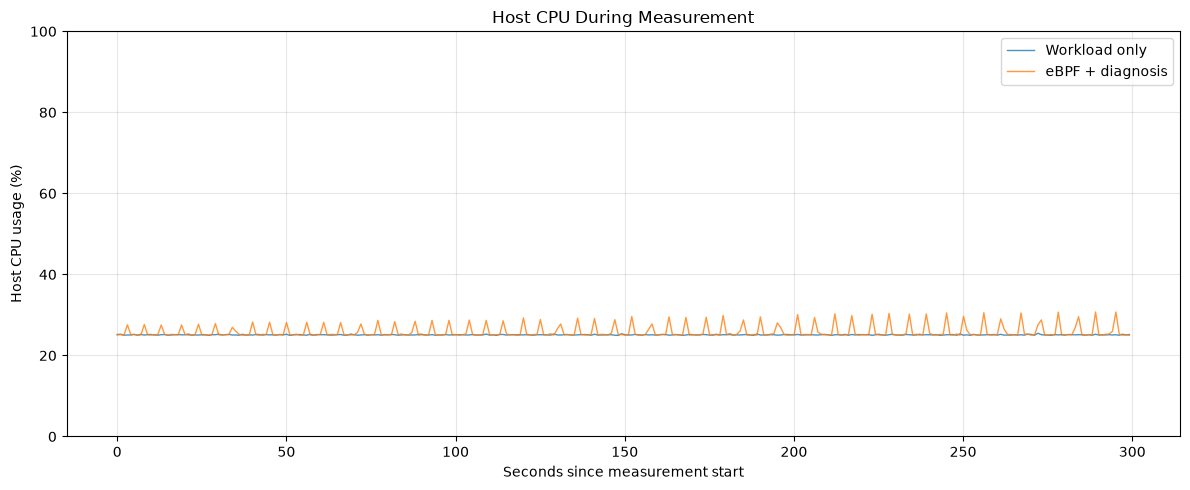

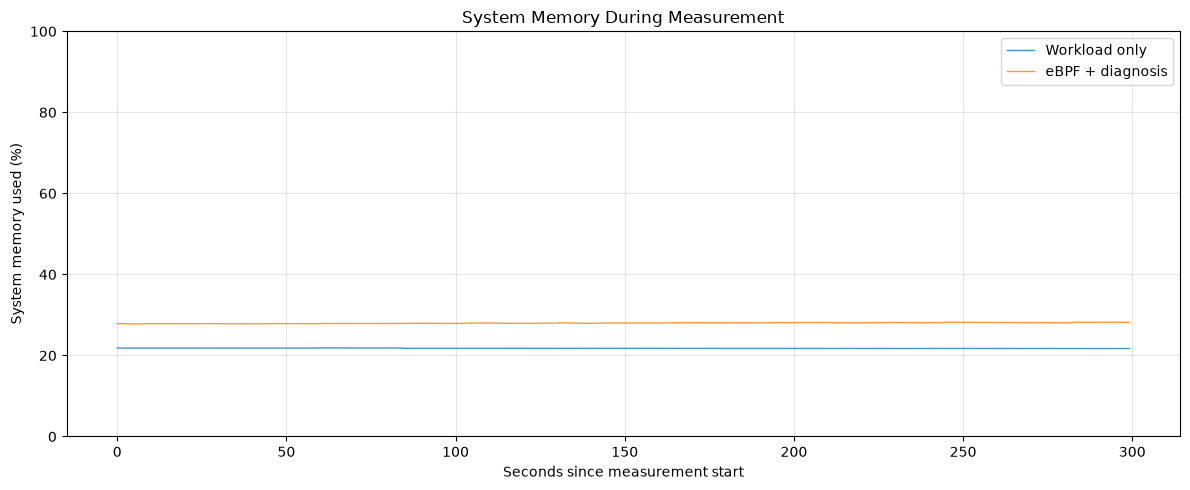

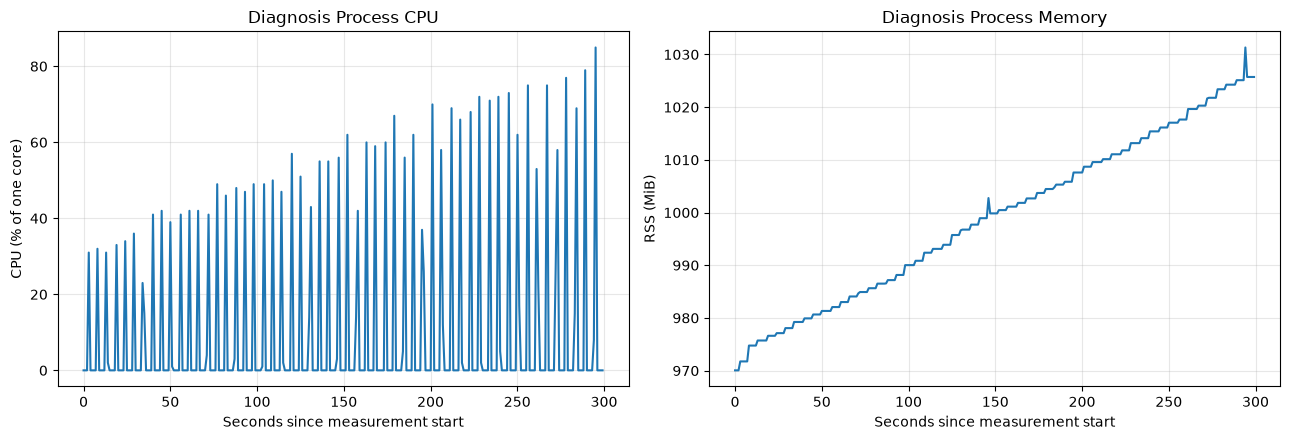


AUTOMATED VERDICT
Host CPU mean: baseline=25.098%, monitored=25.880%, delta=+0.782 percentage points.
Host CPU median delta: +0.047 percentage points.
INVALID/UNVERIFIED: workload-process CPU accounting.
Fix process-tree or worker CPU sampling and rerun.
Memory and host CPU differences are descriptive, not causal proof.
Use multiple matched repetitions before making paper claims.

TOTAL OBSERVED OVERHEAD: eBPF + DIAGNOSIS

Host CPU usage
  Baseline mean:   25.098 percentage points
  Monitored mean:  25.880 percentage points
  Mean difference: +0.782 percentage points
  Baseline median: 25.094 percentage points
  Monitored median: 25.140 percentage points
  Median difference: +0.047 percentage points
  Relative mean change: +3.12%

System memory used
  Baseline mean:   3319.854 MiB
  Monitored mean:  4271.350 MiB
  Mean difference: +951.496 MiB
  Baseline median: 3317.629 MiB
  Monitored median: 4270.684 MiB
  Median difference: +953.055 MiB
  Relative mean change: +28.66%

System memo

In [ ]:

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Locate and load the three benchmark result files
# ============================================================
ROOT = Path.cwd().resolve()
RESULTS_CANDIDATES = [
    base / relative
    for base in (ROOT, *ROOT.parents)
    for relative in (
        Path("runtime_benchmark_results"),
        Path("src/realtime/runtime_benchmark_results"),
    )
]
RESULTS = next(
    (path for path in RESULTS_CANDIDATES if path.is_dir()),
    ROOT / "runtime_benchmark_results",
)

FILES = {
    "resources": RESULTS / "system_resource_metrics.csv",
    "groups": RESULTS / "analysis/group_summary.csv",
    "overhead": RESULTS / "analysis/overhead_summary.csv",
}

# If the notebook is elsewhere, try the uploaded/current-directory CSVs.
FALLBACKS = {
    "resources": Path("system_resource_metrics.csv"),
    "groups": Path("group_summary(1).csv"),
    "overhead": Path("overhead_summary(1).csv"),
}

for key in FILES:
    if not FILES[key].exists() and FALLBACKS[key].exists():
        FILES[key] = FALLBACKS[key]

missing = [str(p) for p in FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing benchmark files:\n" + "\n".join(missing)
        + "\nUpdate FILES at the top of this cell."
    )

resources = pd.read_csv(FILES["resources"])
groups = pd.read_csv(FILES["groups"])
overhead = pd.read_csv(FILES["overhead"])

print("=" * 72)
print("BENCHMARK AUDIT")
print("=" * 72)
print("Resource file:", FILES["resources"])
print("Group summary:", FILES["groups"])
print("Overhead summary:", FILES["overhead"])
print(f"Resource rows: {len(resources):,}")

# ============================================================
# 2. Validate run identity, conditions and sampling completeness
# ============================================================
required = {
    "condition", "phase", "elapsed_s", "system_cpu_percent",
    "system_memory_used_bytes", "system_memory_used_percent",
    "workload_process_cpu_percent_one_core",
    "workload_process_rss_bytes",
    "monitor_process_cpu_percent_one_core",
    "monitor_process_rss_bytes",
    "comparison_id", "workload_workers", "workload_type",
}

missing_cols = required - set(resources.columns)
if missing_cols:
    raise ValueError(f"Missing resource columns: {sorted(missing_cols)}")

print("\nRuns and sample counts:")
print(
    resources.groupby(["run_id", "condition", "phase"], dropna=False)
    .agg(
        samples=("elapsed_s", "size"),
        first_elapsed_s=("elapsed_s", "min"),
        last_elapsed_s=("elapsed_s", "max"),
        workers=("workload_workers", "first"),
        comparison_id=("comparison_id", "first"),
    )
    .to_string()
)

conditions = set(resources["condition"].dropna())
expected = {"workload_only", "ebpf_plus_diagnosis"}
if not expected.issubset(conditions):
    warnings.warn(f"Expected both conditions; found {conditions}")

measurement = resources.loc[
    resources["phase"].astype(str).str.lower().eq("measurement")
].copy()

print("\nMeasurement sample counts:")
print(measurement.groupby(["run_id", "condition"]).size().to_string())

# Compare basic run configuration.
for col in ["workload_type", "workload_workers", "comparison_id",
            "repetition_index"]:
    if col in measurement.columns:
        print(f"\n{col}:")
        print(measurement.groupby("condition")[col].agg(
            lambda x: ", ".join(map(str, pd.unique(x.dropna())))
        ).to_string())

# ============================================================
# 3. Recalculate per-condition resource statistics
#    Use measurement samples only, excluding warm-up.
# ============================================================
metrics = {
    "system_cpu_percent": "Host CPU (%)",
    "system_memory_used_percent": "System memory used (%)",
    "workload_process_cpu_percent_one_core":
        "Recorded workload-process CPU (% of one core)",
    "workload_process_rss_bytes": "Workload-process RSS (MiB)",
    "monitor_process_cpu_percent_one_core":
        "Diagnosis-process CPU (% of one core)",
    "monitor_process_rss_bytes": "Diagnosis-process RSS (MiB)",
}

for col in ["workload_process_rss_bytes", "monitor_process_rss_bytes"]:
    if col in measurement.columns:
        measurement[col.replace("_bytes", "_mib")] = (
            measurement[col] / (1024 ** 2)
        )

summary_rows = []
for condition, frame in measurement.groupby("condition"):
    for col, label in metrics.items():
        actual_col = col
        if col.endswith("_bytes"):
            actual_col = col.replace("_bytes", "_mib")
        if actual_col not in frame.columns:
            continue

        values = pd.to_numeric(frame[actual_col], errors="coerce").dropna()
        summary_rows.append({
            "condition": condition,
            "metric": label,
            "n": len(values),
            "mean": values.mean() if len(values) else np.nan,
            "median": values.median() if len(values) else np.nan,
            "p95": values.quantile(.95) if len(values) else np.nan,
            "max": values.max() if len(values) else np.nan,
            "zero_fraction": (values == 0).mean() if len(values) else np.nan,
        })

stats = pd.DataFrame(summary_rows)
print("\nRESOURCE STATISTICS (measurement phase only)")
display(stats.round(3))

# ============================================================
# 4. Check whether workload CPU sampling is credible
# ============================================================
print("\nWORKLOAD CPU SAMPLING CHECK")
for condition, frame in measurement.groupby("condition"):
    cpu = pd.to_numeric(
        frame["workload_process_cpu_percent_one_core"],
        errors="coerce"
    ).dropna()

    zeros = (cpu == 0).mean() if len(cpu) else np.nan
    print(
        f"{condition}: samples={len(cpu)}, "
        f"mean={cpu.mean() if len(cpu) else np.nan:.3f}%, "
        f"zero samples={zeros:.1%}" if len(cpu) else
        f"{condition}: no valid CPU samples"
    )

    if len(cpu) and zeros > 0.95:
        warnings.warn(
            f"{condition}: over 95% of workload CPU samples are zero. "
            "The sampler may be tracking the stress-ng parent instead "
            "of its CPU workers. Do not use this metric to claim "
            "workload CPU overhead."
        )

# ============================================================
# 5. Compare conditions using the SAME statistic
#    Mean and median are both reported; do not mix them.
# ============================================================
print("\nHOST CPU AND MEMORY DIFFERENCES")
host_rows = []

for col, label in [
    ("system_cpu_percent", "Host CPU (%)"),
    ("system_memory_used_percent", "System memory (%)"),
    ("system_memory_used_bytes", "System memory used (MiB)"),
]:
    if col not in measurement.columns:
        continue

    a = pd.to_numeric(
        measurement.loc[measurement["condition"] == "workload_only", col],
        errors="coerce"
    ).dropna()

    b = pd.to_numeric(
        measurement.loc[
            measurement["condition"] == "ebpf_plus_diagnosis", col
        ],
        errors="coerce"
    ).dropna()

    if col.endswith("_bytes"):
        a, b = a / (1024**2), b / (1024**2)

    if len(a) and len(b):
        host_rows.append({
            "metric": label,
            "baseline_mean": a.mean(),
            "monitored_mean": b.mean(),
            "mean_delta": b.mean() - a.mean(),
            "baseline_median": a.median(),
            "monitored_median": b.median(),
            "median_delta": b.median() - a.median(),
        })

host_comparison = pd.DataFrame(host_rows)
display(host_comparison.round(3))

# ============================================================
# 6. Audit the provided overhead summary
# ============================================================
print("\nEXISTING OVERHEAD SUMMARY")
display(overhead)

if "workload_process_cpu_delta_percentage_points" in overhead.columns:
    vals = pd.to_numeric(
        overhead["workload_process_cpu_delta_percentage_points"],
        errors="coerce"
    )
    if vals.notna().any() and (vals == 0).all():
        print(
            "WARNING: The saved workload CPU delta is zero, but the raw "
            "samples are also zero. This is not evidence of zero overhead; "
            "the underlying workload CPU metric appears invalid."
        )

# ============================================================
# 7. Generate fresh plots from raw measurement samples
# ============================================================
plot_conditions = ["workload_only", "ebpf_plus_diagnosis"]
labels = {
    "workload_only": "Workload only",
    "ebpf_plus_diagnosis": "eBPF + diagnosis",
}

# Plot host CPU over elapsed time.
fig, ax = plt.subplots(figsize=(12, 5))
for condition in plot_conditions:
    frame = measurement[measurement["condition"] == condition].sort_values(
        "elapsed_s"
    )
    if len(frame):
        # Shift each run to its own measurement start.
        t = frame["elapsed_s"] - frame["elapsed_s"].min()
        ax.plot(
            t, frame["system_cpu_percent"],
            label=labels[condition], linewidth=1, alpha=.8
        )

ax.set(
    title="Host CPU During Measurement",
    xlabel="Seconds since measurement start",
    ylabel="Host CPU usage (%)"
)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

# Plot system memory over elapsed time.
fig, ax = plt.subplots(figsize=(12, 5))
for condition in plot_conditions:
    frame = measurement[measurement["condition"] == condition].sort_values(
        "elapsed_s"
    )
    if len(frame):
        t = frame["elapsed_s"] - frame["elapsed_s"].min()
        ax.plot(
            t, frame["system_memory_used_percent"],
            label=labels[condition], linewidth=1, alpha=.8
        )

ax.set(
    title="System Memory During Measurement",
    xlabel="Seconds since measurement start",
    ylabel="System memory used (%)"
)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

# Plot process CPU and memory for the monitored condition.
mon = measurement[
    measurement["condition"] == "ebpf_plus_diagnosis"
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    mon["elapsed_s"] - mon["elapsed_s"].min(),
    mon["monitor_process_cpu_percent_one_core"],
    label="Diagnosis process"
)
axes[0].set(
    title="Diagnosis Process CPU",
    xlabel="Seconds since measurement start",
    ylabel="CPU (% of one core)"
)
axes[0].grid(True, alpha=.3)

axes[1].plot(
    mon["elapsed_s"] - mon["elapsed_s"].min(),
    mon["monitor_process_rss_bytes"] / (1024**2),
    label="Diagnosis process"
)
axes[1].set(
    title="Diagnosis Process Memory",
    xlabel="Seconds since measurement start",
    ylabel="RSS (MiB)"
)
axes[1].grid(True, alpha=.3)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Final automated verdict
# ============================================================
print("\n" + "=" * 72)
print("AUTOMATED VERDICT")
print("=" * 72)

if len(host_comparison):
    row = host_comparison[
        host_comparison["metric"] == "Host CPU (%)"
    ]
    if len(row):
        r = row.iloc[0]
        print(
            f"Host CPU mean: baseline={r['baseline_mean']:.3f}%, "
            f"monitored={r['monitored_mean']:.3f}%, "
            f"delta={r['mean_delta']:+.3f} percentage points."
        )
        print(
            f"Host CPU median delta: "
            f"{r['median_delta']:+.3f} percentage points."
        )

workload_cpu = pd.to_numeric(
    measurement["workload_process_cpu_percent_one_core"],
    errors="coerce"
).dropna()

if len(workload_cpu) and (workload_cpu == 0).mean() > .95:
    print("INVALID/UNVERIFIED: workload-process CPU accounting.")
    print("Fix process-tree or worker CPU sampling and rerun.")
else:
    print("Workload CPU samples are not predominantly zero; verify PID scope.")

print("Memory and host CPU differences are descriptive, not causal proof.")
print("Use multiple matched repetitions before making paper claims.")


# ============================================================
# 9. TOTAL OVERHEAD: eBPF + diagnosis vs workload-only
# ============================================================

print("\n" + "=" * 72)
print("TOTAL OBSERVED OVERHEAD: eBPF + DIAGNOSIS")
print("=" * 72)

baseline = measurement[
    measurement["condition"] == "workload_only"
].copy()

monitored = measurement[
    measurement["condition"] == "ebpf_plus_diagnosis"
].copy()

if baseline.empty or monitored.empty:
    print("Cannot calculate overhead: one or both conditions have no samples.")
else:
    def describe_metric(frame, column):
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        values = values[np.isfinite(values)]
        if values.empty:
            return {"mean": np.nan, "median": np.nan, "p95": np.nan}
        return {
            "mean": values.mean(),
            "median": values.median(),
            "p95": values.quantile(0.95),
        }

    def compare_metric(label, column, unit="", scale=1.0):
        if column not in baseline.columns or column not in monitored.columns:
            print(f"\n{label}: unavailable ({column} missing)")
            return

        b = describe_metric(baseline, column)
        m = describe_metric(monitored, column)

        print(f"\n{label}")
        print(f"  Baseline mean:   {b['mean'] * scale:.3f} {unit}")
        print(f"  Monitored mean:  {m['mean'] * scale:.3f} {unit}")
        print(f"  Mean difference: {(m['mean'] - b['mean']) * scale:+.3f} {unit}")
        print(f"  Baseline median: {b['median'] * scale:.3f} {unit}")
        print(f"  Monitored median:{m['median'] * scale: .3f} {unit}")
        print(f"  Median difference: {(m['median'] - b['median']) * scale:+.3f} {unit}")

        if np.isfinite(b["mean"]) and np.isfinite(m["mean"]):
            if abs(b["mean"]) > 1e-12:
                relative = (m["mean"] - b["mean"]) / abs(b["mean"]) * 100
                print(f"  Relative mean change: {relative:+.2f}%")
            else:
                print("  Relative mean change: undefined (baseline is zero)")

    # Overall host-level changes
    compare_metric(
        "Host CPU usage",
        "system_cpu_percent",
        unit="percentage points"
    )
    compare_metric(
        "System memory used",
        "system_memory_used_bytes",
        unit="MiB",
        scale=1 / (1024 ** 2)
    )
    compare_metric(
        "System memory utilization",
        "system_memory_used_percent",
        unit="percentage points"
    )

    # Direct monitor resource consumption
    compare_metric(
        "Diagnosis process CPU",
        "monitor_process_cpu_percent_one_core",
        unit="% of one logical CPU"
    )
    compare_metric(
        "Diagnosis process RSS",
        "monitor_process_rss_bytes",
        unit="MiB",
        scale=1 / (1024 ** 2)
    )

    # Workload CPU: explicitly flag invalid measurements
    if "workload_process_cpu_percent_one_core" in monitored.columns:
        wcpu = pd.to_numeric(
            monitored["workload_process_cpu_percent_one_core"],
            errors="coerce"
        ).dropna()

        if wcpu.empty or (wcpu == 0).mean() > 0.95:
            print("\nWorkload CPU overhead: NOT VALIDLY MEASURED")
            print("Most monitored workload CPU samples are zero or missing.")
            print("Fix worker/process-tree CPU accounting and rerun.")
        else:
            compare_metric(
                "Workload process CPU",
                "workload_process_cpu_percent_one_core",
                unit="% of one logical CPU"
            )

    # Throughput comparison, only if a suitable metric is present.
    # Higher throughput is better, so a reduction indicates degradation.
    throughput_candidates = [
        "throughput_ops_per_s",
        "bogo_ops_per_s",
        "workload_throughput",
    ]

    throughput_col = next(
        (c for c in throughput_candidates
         if c in baseline.columns and c in monitored.columns),
        None
    )

    if throughput_col:
        b = describe_metric(baseline, throughput_col)
        m = describe_metric(monitored, throughput_col)

        print(f"\nWorkload throughput ({throughput_col})")
        print(f"  Baseline mean:  {b['mean']:.3f}")
        print(f"  Monitored mean: {m['mean']:.3f}")

        if np.isfinite(b["mean"]) and abs(b["mean"]) > 1e-12:
            degradation = (b["mean"] - m["mean"]) / abs(b["mean"]) * 100
            print(f"  Throughput degradation: {degradation:+.2f}%")
        else:
            print("  Throughput degradation: cannot calculate")
    else:
        print("\nWorkload throughput: not present in resource samples.")
        print("Use the stress-ng final bogo-ops/s from each run instead.")

    print("\nINTERPRETATION")
    print("- Host CPU/memory differences are system-level changes.")
    print("- Diagnosis CPU/RSS measure the monitor process directly.")
    print("- Do not sum these metrics into a single overhead percentage.")
    print("- Use matched repetitions and valid workload CPU measurements")
    print("  before making claims about total monitoring overhead.")


In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

inference_col = next(
    (col for col in ("rf_inference_ms", "classifier_inference_ms") if col in cycles.columns),
    None,
)
required = {"phase", "cycle_status", "records_processed"}

if inference_col is None or not required.issubset(cycles.columns):
    raise ValueError(
        f"cycle_metrics.csv needs an inference-time column, {sorted(required)}; "
        f"found: {cycles.columns.tolist()}"
    )

per_cycle = cycles.loc[
    cycles["phase"].eq("measurement")
    & cycles["cycle_status"].eq("completed")
].copy()

per_cycle["inference_ms"] = pd.to_numeric(per_cycle[inference_col], errors="coerce")
per_cycle["rows"] = pd.to_numeric(per_cycle["records_processed"], errors="coerce")
per_cycle = per_cycle.dropna(subset=["inference_ms", "rows"])
per_cycle = per_cycle.loc[per_cycle["rows"] > 0]

if per_cycle.empty:
    raise ValueError("No completed measurement cycles have valid inference times and row counts.")

# Amortized inference time per row for each batch; not isolated single-row latency.
per_cycle["amortized_ms_per_row"] = per_cycle["inference_ms"] / per_cycle["rows"]
per_cycle["amortized_ns_per_row"] = per_cycle["amortized_ms_per_row"] * 1_000_000

# Weighted across all rows, so larger batches contribute proportionally.
total_rows = per_cycle["rows"].sum()
weighted_ms_per_row = per_cycle["inference_ms"].sum() / total_rows

summary = pd.DataFrame([{
    "measurement_cycles": len(per_cycle),
    "total_rows_processed": int(total_rows),
    "mean_batch_inference_ms": per_cycle["inference_ms"].mean(),
    "weighted_amortized_ms_per_row": weighted_ms_per_row,
    "weighted_amortized_ns_per_row": weighted_ms_per_row * 1_000_000,
    "mean_of_cycle_ms_per_row": per_cycle["amortized_ms_per_row"].mean(),
    "mean_of_cycle_ns_per_row": per_cycle["amortized_ns_per_row"].mean(),
}])

display(summary.round(6))

,measurement_cycles,total_rows_processed,mean_batch_inference_ms,weighted_amortized_ms_per_row,weighted_amortized_ns_per_row,mean_of_cycle_ms_per_row,mean_of_cycle_ns_per_row
0,56,212973,113.243411,0.029777,29776.689956,0.034081,34081.167654


In [ ]:
measurement = cycles.loc[
    cycles["phase"].eq("measurement")
    & cycles["cycle_status"].eq("completed")
].copy()

rows = pd.to_numeric(measurement["records_processed"], errors="coerce").dropna()

print(f"Completed measurement cycles: {len(rows)}")
print(f"Average rows per cycle: {rows.mean():,.2f}")

Completed measurement cycles: 56
Average rows per cycle: 3,803.09
